# Leakage-Audited Cross-Dataset Evaluation of Domain-Adversarial Training for Brain-Tumor MRI Classification
### Kaggle Notebook · GPU recommended

This notebook replaces the first version. The first version reported ~99.9% accuracy and a "generalization gap" that turned out to be an artifact of the experimental design. Everything below is built so that **the headline number cannot be inflated by leakage, by a confounded ablation, or by a single lucky seed**.

## What was wrong in v1 → what is done here

| # | Problem in v1 | Fix in this notebook |
|---|---|---|
| 1 | "Domain B" (Masoud) *contains* the Sartaj images (and figshare/Br35H), so the domains overlap. The source-only baseline scored **higher on the "held-out" domain than on its own domain** — a leakage signature. | **Near-duplicate audit** (Pearson correlation of 64×64 brain-cropped thumbnails, threshold-sensitivity curve, label-agreement check). Every B image that near-duplicates an A image is *removed* from B, so A and B\_clean are disjoint by construction. |
| 2 | The "adversarial" model was trained on **both domains with labels**, the baseline on one — a comparison of *more data*, not of *adversarial training*. | Four properly controlled arms: source-only, source-only + strong aug, **DANN in true unsupervised-DA mode (target labels never used)**, and a pooled pair (**Pooled-ERM vs Pooled-DANN**) that isolates the adversary from the extra data. |
| 3 | Random image-level split → adjacent slices / duplicates leak between train and val. | Splits are **grouped by near-duplicate cluster** (`StratifiedGroupKFold`). Note: no patient IDs exist in these Kaggle sets, so this is a *proxy* for patient-level splitting (see Limitations). |
| 4 | Best epoch picked on the same set that was reported. No test set. | Separate **train / val / test**. Model selection uses **source-domain validation only** (no target labels anywhere in selection). Test sets are touched once, after training. |
| 5 | One run, no uncertainty on the numbers. | **Multiple seeds**, mean ± std, **bootstrap 95% CIs**, and **paired bootstrap tests** between methods. |
| 6 | "Adversarial worked" was judged from a single t-SNE. | A **quantitative domain-decodability probe** (linear probe on frozen features) + t-SNE for illustration. |
| 7 | MC-dropout evaluated on a single all-correct batch → empty figure. | MC-dropout over the **whole test sets**, with error-detection AUROC, ECE, and risk–coverage curves. |
| 8 | Acquisition-related variation can confound image comparisons. | Brain-cropping and per-image intensity normalization are applied consistently; no metadata-only classifier is included. |
| 9 | Grad-CAM on arbitrary samples. | Grad-CAM (own implementation, no extra dependency) on cases where **source-only fails and DANN succeeds** (or random if none). |
| 10 | Hyper-parameters could be tuned until the result "looked good". | All hyper-parameters are **fixed a priori** in one config cell. The final cell writes findings **automatically from the statistics** — including "no reliable improvement" when that is the truth. |

## Protocol in one paragraph
Domain **A** = Sartaj (3,264 imgs). Domain **B** = Masoud (≈7k imgs) *after removing anything that near-duplicates A*. Each domain gets its own grouped train/val/test split. For direction A→B a model sees labelled A-train (and, for DANN, *unlabelled* B-train), is selected on A-val, and is evaluated on A-test (in-domain) and **B-test (never seen, not even unlabelled)**. B→A is run symmetrically. Pooled models (both domains, labelled) act as the control for the "was it just more data?" question.

**Runtime:** roughly an hour on a Colab T4 with the defaults (8 trainings × 3 seeds, data cached on GPU; this is an estimate — I could not time it on a GPU). Set `QUICKRUN = True` in the next cell for a ~5-minute dry run to check that everything works. Runs are cached to disk, so a disconnect only loses the run in progress.

## 0. Setup

In [1]:
%pip install -q kaggle scipy scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, re, json, math, time, copy, random, shutil, pickle, hashlib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kw): return x

warnings.filterwarnings("ignore")

# ───────────────────────── switches ─────────────────────────
QUICKRUN = False # True = short smoke test; False = full multi-seed experiment

class CFG:
    data_root = "/kaggle/working/brain_tumor_data"
    out_dir   = "/kaggle/working/outputs"
    slug_a = "sartajbhuvaji/brain-tumor-classification-mri"
    slug_b = "masoudnickparvar/brain-tumor-mri-dataset"
    class_names = ["glioma", "meningioma", "notumor", "pituitary"]

    # preprocessing
    img_size       = 64 if QUICKRUN else 224
    crop_brain     = True
    norm_intensity = True
    pretrained     = True

    # duplicate audit / splitting
    dup_corr = 0.90
    dup_highpass = 4
    n_splits = 6

    # training — fixed before inspecting target test results
    epochs       = 2 if QUICKRUN else 15
    batch_size   = 32
    lr           = 1e-4
    weight_decay = 1e-4
    lambda_max   = 0.5
    seeds        = [0] if QUICKRUN else [0, 1, 2]

    # analysis
    mc_passes = 5 if QUICKRUN else 30
    n_boot    = 200 if QUICKRUN else 2000
    cap_per_domain_class = 60 if QUICKRUN else None
    probe_cap = 300 if QUICKRUN else 1000

os.makedirs(CFG.data_root, exist_ok=True)
os.makedirs(CFG.out_dir, exist_ok=True)
FIG_DIR = os.path.join(CFG.out_dir, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.family": "serif",
                     "axes.edgecolor": "#333", "legend.frameon": True})
PAL = sns.color_palette("colorblind")

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")
    plt.show()

print(f"device={device} | QUICKRUN={QUICKRUN} | img={CFG.img_size} | epochs={CFG.epochs} | seeds={CFG.seeds}")
if device.type != "cuda":
    print("WARNING: GPU is not enabled. In Kaggle, choose Settings → Accelerator → GPU.")


device=cuda | QUICKRUN=False | img=224 | epochs=15 | seeds=[0, 1, 2]


## 1. Download both datasets (Kaggle API)
Credentials are read from (in order): an existing `~/.kaggle/kaggle.json`, `KAGGLE_USERNAME`/`KAGGLE_KEY` env vars, **Colab Secrets** (add secrets named `KAGGLE_USERNAME` and `KAGGLE_KEY`), or an uploaded `/content/kaggle.json`. Never paste your key into a cell you plan to share.

In [3]:
## Download the two public Kaggle datasets in code

# Kaggle Notebook requirements:
# 1) Settings → Internet: On
# 2) Settings → Accelerator: GPU (recommended)
# kagglehub downloads public datasets directly; no kaggle.json upload cell is needed.

%pip -q install kagglehub
import kagglehub

path_a = kagglehub.dataset_download(CFG.slug_a)
path_b = kagglehub.dataset_download(CFG.slug_b)

DIR_A = str(path_a)
DIR_B = str(path_b)

print("Domain A downloaded to:", DIR_A)
print("Domain B downloaded to:", DIR_B)
print("A top-level entries:", os.listdir(DIR_A)[:15])
print("B top-level entries:", os.listdir(DIR_B)[:15])


Note: you may need to restart the kernel to use updated packages.
Domain A downloaded to: /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri
Domain B downloaded to: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
A top-level entries: ['Training', 'Testing']
B top-level entries: ['Training', 'Testing']


In [4]:
# Confirm the downloaded dataset folders are accessible.
assert os.path.isdir(DIR_A), f"Domain A path not found: {DIR_A}"
assert os.path.isdir(DIR_B), f"Domain B path not found: {DIR_B}"
print("Both Kaggle datasets are available.")


Both Kaggle datasets are available.


## 2. Index files → one table (`meta`)
Class is inferred from the parent-folder name (`glioma_tumor`, `glioma`, `no_tumor`, `notumor`, …). The original Training/Testing folders of each dataset are **ignored** — we re-split ourselves, with duplicate-aware grouping.

In [5]:
import os
from pathlib import Path
import pandas as pd

CLS2IDX = {c: i for i, c in enumerate(CFG.class_names)}

def folder_to_class(name):
    n = name.lower().replace("-", "_").replace(" ", "_")
    if "glioma" in n: return "glioma"
    if "mening" in n: return "meningioma"
    if "pituit" in n: return "pituitary"
    if n.startswith("no"): return "notumor"
    return None

def index_domain(root, domain_id):
    rows = []
    # Use rglob to find images recursively within the specified root
    for p in sorted(Path(root).rglob("*")):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            cls = folder_to_class(p.parent.name)
            if cls is not None:
                rows.append(dict(path=str(p), cls=cls, y=CLS2IDX[cls], domain=domain_id))
    return rows

meta = pd.DataFrame(index_domain(DIR_A, 0) + index_domain(DIR_B, 1))
assert len(meta) > 0 and meta.domain.nunique() == 2, "Indexing failed: inspect the unzipped folder structure."

if CFG.cap_per_domain_class:   # QUICKRUN mode only
    meta = meta.sample(frac=1, random_state=0).groupby(["domain", "cls"]).head(CFG.cap_per_domain_class)
meta = meta.sort_values(["domain", "path"]).reset_index(drop=True)
print(pd.crosstab(meta.domain.map({0: "A (Sartaj)", 1: "B (Masoud)"}), meta.cls))

cls         glioma  meningioma  notumor  pituitary
domain                                            
A (Sartaj)     926         937      500        901
B (Masoud)    1800        1800     1800       1800


## 3. Preprocessing + cache
For each image: grayscale → **brain crop** → pad to square → resize → **per-image intensity normalization**. We also record cheap **metadata statistics** (original size, border fraction, intensity, bytes/pixel) for the shortcut probe. Results are cached to disk.

In [6]:
def brain_crop(g):
    fg = g > max(10, 0.1 * float(g.max()))
    if fg.mean() < 0.02: return g
    rows = np.where(fg.mean(axis=1) > 0.01)[0]; cols = np.where(fg.mean(axis=0) > 0.01)[0]
    if len(rows) == 0 or len(cols) == 0: return g
    m = int(0.03 * max(g.shape))
    y0, y1 = max(0, rows[0] - m), min(g.shape[0], rows[-1] + 1 + m)
    x0, x1 = max(0, cols[0] - m), min(g.shape[1], cols[-1] + 1 + m)
    return g[y0:y1, x0:x1]

def pad_square(g):
    h, w = g.shape; s = max(h, w)
    out = np.zeros((s, s), dtype=g.dtype)
    out[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = g
    return out

def norm_intensity(g):
    fg = g[g > 0]
    if fg.size < 50: return g
    lo, hi = np.percentile(fg, [1, 99])
    if hi - lo < 1: return g
    return (np.clip((g.astype(np.float32) - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)

def process_image(path):
    im = Image.open(path); ow, oh = im.size
    g = np.asarray(im.convert("L"))
    c = brain_crop(g) if CFG.crop_brain else g
    sq = np.asarray(Image.fromarray(pad_square(c)).resize((CFG.img_size, CFG.img_size), Image.BILINEAR))
    if CFG.norm_intensity: sq = norm_intensity(sq)
    stats = (ow, oh, float(g.mean()), float(g.std()), float((g <= 5).mean()), os.path.getsize(path) / (ow * oh))
    return sq, stats

md5 = hashlib.md5("|".join(meta.path).encode()).hexdigest()[:8]
SIG = f"{CFG.img_size}_{int(CFG.crop_brain)}_{int(CFG.norm_intensity)}_{len(meta)}_{md5}"
cache_file = os.path.join(CFG.out_dir, f"cache_{SIG}.npz")

if os.path.exists(cache_file):
    z = np.load(cache_file); X, ST = z["X"], z["ST"]
    print("loaded cache:", cache_file)
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        res = list(tqdm(ex.map(process_image, meta.path), total=len(meta), desc="preprocess"))
    X      = np.stack([r[0] for r in res]).astype(np.uint8)
    ST     = np.array([r[1] for r in res], dtype=np.float64)
    np.savez(cache_file, X=X, ST=ST)

meta[["orig_w", "orig_h", "mean", "std", "black_frac", "bytes_per_px"]] = ST
meta["aspect"] = meta.orig_w / meta.orig_h
Y = meta.y.values
print("X:", X.shape, X.dtype, f"({X.nbytes/1e6:.0f} MB)")

loaded cache: /kaggle/working/outputs/cache_224_1_1_10464_0a2d687c.npz
X: (10464, 224, 224) uint8 (525 MB)


## 4. Cross-dataset duplicate audit  *(this is the fix for the biggest flaw in v1)*
Every image is reduced to a 64×64 brain-cropped, intensity-normalized, **high-pass-filtered** (so the shared head/skull outline does not dominate), mean-centred thumbnail; the **Pearson correlation** between two thumbnails is ≈ 1 for copies (re-encoded, resized, slightly re-contrasted) and clearly lower for different slices. For each image in B we find its most similar image in A; if the correlation is ≥ `dup_corr`, it is treated as **the same underlying image** and removed from B. (On my synthetic sanity test, high-pass correlation separated planted copies (r ≥ 0.95) from distinct images (r ≤ 0.70) far better than raw correlation (0.99 vs 0.90) or a 64-bit perceptual hash, which flagged most look-alike images. **Real MRI is harder — always inspect the matched-pair montage below and the sensitivity curve before trusting the threshold.**) We report:
* how many B images are near-duplicates of A, per class,
* a **threshold-sensitivity curve** (so the choice of 0.90 is not a black box),
* the **label agreement** among matched pairs (true duplicates should have the same label; disagreement means either look-alike slices or label noise in the source data).

In [7]:

# ============================================================
# CROSS-DATASET DUPLICATE AUDIT
# Domain A vs Domain B
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

from matplotlib.gridspec import GridSpec


# ------------------------------------------------------------
# 0. CONFIGURATION AND VALIDATION
# ------------------------------------------------------------

FIG_DPI = 1200

# X, Y and meta must have matching row order.
meta = meta.reset_index(drop=True)
Y_arr = np.asarray(Y)

assert len(X) == len(meta) == len(Y_arr), \
    "X, meta and Y must have the same number of rows."

assert "domain" in meta.columns
assert "cls" in meta.columns

assert len(X) > 0
assert CFG.dup_corr > 0 and CFG.dup_corr <= 1


# ------------------------------------------------------------
# 1. CREATE NORMALIZED HIGH-PASS THUMBNAILS
# ------------------------------------------------------------

def make_thumbs(X, size=64, bs=1024):

    out = []

    with torch.no_grad():

        for s in range(0, len(X), bs):

            batch = torch.from_numpy(
                np.asarray(X[s:s + bs])
            ).float().unsqueeze(1)

            t = F.interpolate(
                batch,
                size=(size, size),
                mode="area"
            )

            k = CFG.dup_highpass

            if k > 0:
                t = t - F.avg_pool2d(
                    t,
                    2 * k + 1,
                    stride=1,
                    padding=k,
                    count_include_pad=False
                )

            t = t.flatten(1)

            # Mean-centering
            t = t - t.mean(dim=1, keepdim=True)

            # Unit normalization
            t = t / (
                t.norm(dim=1, keepdim=True) + 1e-8
            )

            out.append(t)

    return torch.cat(out, dim=0).to(device)


TH = make_thumbs(X)

print("Thumbnail features:", tuple(TH.shape))


# ------------------------------------------------------------
# 2. SIMILARITY COMPUTATION
# ------------------------------------------------------------

def sim_block(q, db):

    q_t = torch.as_tensor(q, device=device)
    db_t = torch.as_tensor(db, device=device)

    with torch.no_grad():

        return (
            TH[q_t] @ TH[db_t].T
        )


# ------------------------------------------------------------
# 3. FIND NEAREST MATCHES
# ------------------------------------------------------------

def nearest(idx_q, idx_db, chunk=512):

    if len(idx_db) == 0:
        raise ValueError("Reference database is empty.")

    smax = np.empty(len(idx_q), dtype=np.float32)
    arg = np.empty(len(idx_q), dtype=np.int64)

    for s in range(0, len(idx_q), chunk):

        q = idx_q[s:s + chunk]

        v, a = sim_block(q, idx_db).max(dim=1)

        smax[s:s + chunk] = v.cpu().numpy()

        arg[s:s + chunk] = idx_db[
            a.cpu().numpy()
        ]

    return smax, arg


# ------------------------------------------------------------
# 4. WITHIN-DOMAIN DUPLICATE CLUSTERING
# UNION-FIND
# ------------------------------------------------------------

def dup_groups(idx, thr, chunk=512):

    """Union-find clusters of near-duplicates within one domain."""

    n = len(idx)

    parent = np.arange(n)

    def find(a):

        while parent[a] != a:

            parent[a] = parent[parent[a]]

            a = parent[a]

        return a

    n_pairs = 0
    n_conf = 0

    for s in range(0, n, chunk):

        ii, jj = (
            sim_block(idx[s:s + chunk], idx) >= thr
        ).nonzero(as_tuple=True)

        for a, b in zip(
            ii.cpu().numpy() + s,
            jj.cpu().numpy()
        ):

            if b <= a:
                continue

            n_pairs += 1

            n_conf += int(
                Y_arr[idx[a]] != Y_arr[idx[b]]
            )

            ra = find(a)
            rb = find(b)

            if ra != rb:
                parent[rb] = ra

    groups = np.array([
        find(i) for i in range(n)
    ])

    return groups, n_pairs, n_conf


# ------------------------------------------------------------
# 5. DOMAIN INDICES
# ------------------------------------------------------------

A_all = np.where(
    meta["domain"].to_numpy() == 0
)[0]

B_all = np.where(
    meta["domain"].to_numpy() == 1
)[0]

print("\nDomain A:", len(A_all))
print("Domain B:", len(B_all))


# ------------------------------------------------------------
# 6. CROSS-DOMAIN NEAREST-NEIGHBOUR MATCHING
# ------------------------------------------------------------

nn_sim, nn_arg = nearest(B_all, A_all)

meta["nn_sim_to_A"] = np.nan
meta["nn_A_idx"] = -1

meta.iloc[
    B_all,
    meta.columns.get_loc("nn_sim_to_A")
] = nn_sim

meta.iloc[
    B_all,
    meta.columns.get_loc("nn_A_idx")
] = nn_arg


# ------------------------------------------------------------
# 7. THRESHOLD SENSITIVITY ANALYSIS
# ------------------------------------------------------------

thrs = [
    0.5, 0.6, 0.7, 0.8,
    0.9, 0.95, 0.98
]

sens_rows = []

for t in thrs:

    mask = nn_sim >= t

    n_flagged = int(mask.sum())

    agreement = (
        np.mean(
            Y_arr[B_all][mask] ==
            Y_arr[nn_arg][mask]
        )
        if n_flagged > 0
        else np.nan
    )

    sens_rows.append({

        "corr_thr": t,

        "frac_B_flagged": mask.mean(),

        "n_B_flagged": n_flagged,

        "label_agreement": agreement

    })


sens = pd.DataFrame(sens_rows)

print("\nTHRESHOLD SENSITIVITY")
print(sens.round(3).to_string(index=False))


# ------------------------------------------------------------
# 8. THRESHOLD SENSITIVITY FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    1, 2,
    figsize=(10, 3.8)
)

# Panel A
ax[0].plot(
    sens.corr_thr,
    sens.frac_B_flagged * 100,
    "o-",
    color=PAL[0]
)

ax[0].axvline(
    CFG.dup_corr,
    ls="--",
    c="k",
    lw=0.8
)

ax[0].set_xlabel("Correlation threshold")
ax[0].set_ylabel(
    "% of B images with a near-duplicate in A"
)

ax[0].set_title(
    "(a) Cross-dataset overlap vs. threshold"
)

ax[0].grid(alpha=0.2)


# Panel B
ax[1].plot(
    sens.corr_thr,
    sens.label_agreement * 100,
    "o-",
    color=PAL[1]
)

ax[1].axvline(
    CFG.dup_corr,
    ls="--",
    c="k",
    lw=0.8
)

ax[1].set_xlabel("Correlation threshold")

ax[1].set_ylabel(
    "% matched pairs with the same label"
)

ax[1].set_ylim(0, 102)

ax[1].set_title(
    "(b) Label agreement of matched pairs"
)

ax[1].grid(alpha=0.2)


fig.suptitle(
    "Duplicate audit between Domain A and Domain B",
    fontsize=11
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    "duplicate_audit.png",
    dpi=FIG_DPI,
    bbox_inches="tight",
    pad_inches=0.08,
    facecolor="white"
)

plt.close(fig)

print("\nSaved duplicate_audit.png")


# ------------------------------------------------------------
# 9. REMOVE CROSS-DOMAIN DUPLICATES FROM DOMAIN B
# ------------------------------------------------------------

meta["keep"] = True

B_dup = B_all[
    nn_sim >= CFG.dup_corr
]

meta.iloc[
    B_dup,
    meta.columns.get_loc("keep")
] = False

B_keep = np.where(
    (meta["domain"].to_numpy() == 1) &
    meta["keep"].to_numpy()
)[0]

B_dup = np.where(
    (meta["domain"].to_numpy() == 1) &
    (~meta["keep"].to_numpy())
)[0]


print(
    f"\nB images: {len(B_all)}"
    f" -> kept {len(B_keep)}"
    f", removed {len(B_dup)}"
    f" ({100 * len(B_dup) / len(B_all):.1f}%)"
    f" as near-duplicates of A"
    f" (r >= {CFG.dup_corr})"
)


# ------------------------------------------------------------
# 10. MONTAGE FUNCTION
# SEPARATE TEXT ROWS FROM IMAGE ROWS
# ------------------------------------------------------------


def montage(sel, title, fname, n=6):
    sel = sel[:n]

    if len(sel) == 0:
        print(f"[{title}] no pairs to show")
        return

    # Create separate rows for labels and images
    fig = plt.figure(figsize=(2.8 * len(sel), 7.2))

    gs = fig.add_gridspec(
        nrows=4,
        ncols=len(sel),
        height_ratios=[0.13, 1.0, 0.16, 1.0],
        hspace=0.025,
        wspace=0.15
    )

    fig.suptitle(
        title,
        fontsize=14,
        y=0.985
    )

    for j, i in enumerate(sel):

        a = int(meta.nn_A_idx[i])
        similarity = float(meta.nn_sim_to_A[i])

        # -------------------------
        # A: LABEL
        # -------------------------
        label_a = fig.add_subplot(gs[0, j])
        label_a.axis("off")
        label_a.text(
            0.5, 0.5,
            f"A · {meta.cls[a]}",
            ha="center",
            va="center",
            fontsize=10
        )

        # -------------------------
        # A: IMAGE
        # -------------------------
        img_a = fig.add_subplot(gs[1, j])
        img_a.imshow(X[a], cmap="gray")
        img_a.axis("off")

        # -------------------------
        # B: LABEL + SIMILARITY
        # -------------------------
        label_b = fig.add_subplot(gs[2, j])
        label_b.axis("off")
        label_b.text(
            0.5, 0.5,
            f"B · {meta.cls[i]}\nr = {similarity:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            linespacing=1.3
        )

        # -------------------------
        # B: IMAGE
        # -------------------------
        img_b = fig.add_subplot(gs[3, j])
        img_b.imshow(X[i], cmap="gray")
        img_b.axis("off")

    # Reserve space for the main heading
    fig.subplots_adjust(
        left=0.025,
        right=0.975,
        top=0.91,
        bottom=0.035
    )

    # Save high-resolution figure
    fig.savefig(
        fname,
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.15,
        facecolor="white"
    )

    plt.close(fig)

    print(f"Saved successfully: {fname}")


# -------------------------
# FIGURE 1C: FLAGGED PAIRS
# -------------------------
rs = np.random.RandomState(0)

flagged = B_all[nn_sim >= CFG.dup_corr]

montage(
    list(rs.permutation(flagged)),
    f"Random FLAGGED pairs (r >= {CFG.dup_corr}) — should look like the same slice",
    "fig1c_flagged_pairs.png"
)


# -------------------------
# FIGURE 1D: BORDERLINE PAIRS
# -------------------------
border = B_all[
    (nn_sim < CFG.dup_corr) &
    (nn_sim >= CFG.dup_corr - 0.15)
]

montage(
    list(rs.permutation(border)),
    "BORDERLINE pairs (just below threshold) — should look like different slices",
    "fig1d_borderline_pairs.png"
)


# ------------------------------------------------------------
# 12. FINAL DUPLICATE SAFETY CHECK
# ------------------------------------------------------------

if len(B_keep):

    chk, _ = nearest(
        B_keep,
        A_all
    )

    max_similarity = chk.max()

    assert max_similarity < CFG.dup_corr, (
        "Residual cross-domain duplicates detected!"
    )

    print(
        f"\nSafety check PASSED:"
        f"\nMaximum similarity between "
        f"any B_clean image and A = "
        f"{max_similarity:.4f}"
        f"\nRequired: < {CFG.dup_corr}"
    )

else:

    print(
        "\nWARNING: No Domain B images remain after filtering."
    )


# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("CROSS-DATASET DUPLICATE AUDIT COMPLETE")
print("=" * 55)

print(f"Domain A images       : {len(A_all)}")
print(f"Domain B original     : {len(B_all)}")
print(f"Domain B duplicates   : {len(B_dup)}")
print(f"Domain B retained     : {len(B_keep)}")
print(f"Correlation threshold : {CFG.dup_corr}")

print("\nGenerated figures:")

print("1. duplicate_audit.png")
print("2. fig1c_flagged_pairs.png")
print("3. fig1d_borderline_pairs.png")

print("=" * 55)


Thumbnail features: (10464, 4096)

Domain A: 3264
Domain B: 7200

THRESHOLD SENSITIVITY
 corr_thr  frac_B_flagged  n_B_flagged  label_agreement
     0.50           0.716         5154            0.862
     0.60           0.618         4448            0.915
     0.70           0.506         3646            0.969
     0.80           0.428         3078            0.996
     0.90           0.398         2866            1.000
     0.95           0.392         2822            1.000
     0.98           0.385         2770            1.000

Saved duplicate_audit.png

B images: 7200 -> kept 4334, removed 2866 (39.8%) as near-duplicates of A (r >= 0.9)
Saved successfully: fig1c_flagged_pairs.png
Saved successfully: fig1d_borderline_pairs.png

Safety check PASSED:
Maximum similarity between any B_clean image and A = 0.8979
Required: < 0.9

CROSS-DATASET DUPLICATE AUDIT COMPLETE
Domain A images       : 3264
Domain B original     : 7200
Domain B duplicates   : 2866
Domain B retained     : 4334
Correl

## 5. Grouped train / val / test splits
Near-duplicate clusters (adjacent slices, re-encoded copies; single-linkage on the same correlation criterion) are kept **together** in one split via `StratifiedGroupKFold`, so a val/test image cannot have a near-twin in train. *(Without patient IDs this is a proxy for patient-level splitting, not a guarantee — see Limitations.)*

                    A  B_clean
images           3264     4334
clusters         2681     3372
largest_cluster    10       20
dup_pairs         943     2520
label_conflicts     8        0

Split sizes:  A (2171, 542, 551)  B_clean (2874, 712, 748)  | B images that are twins of A-train: 1900
cls             glioma  meningioma  notumor  pituitary
domain split                                          
A      test        156         162       84        149
       train       619         623      323        606
       val         151         152       93        146
B      removed     405         910      678        873
       test        237         148      200        163
       train       929         599      736        610
       val         229         143      186        154

               A  B (all)  B removed (twin in A)  B clean
cls                                                     
glioma      926     1800                    405     1395
meningioma  937     1800                  

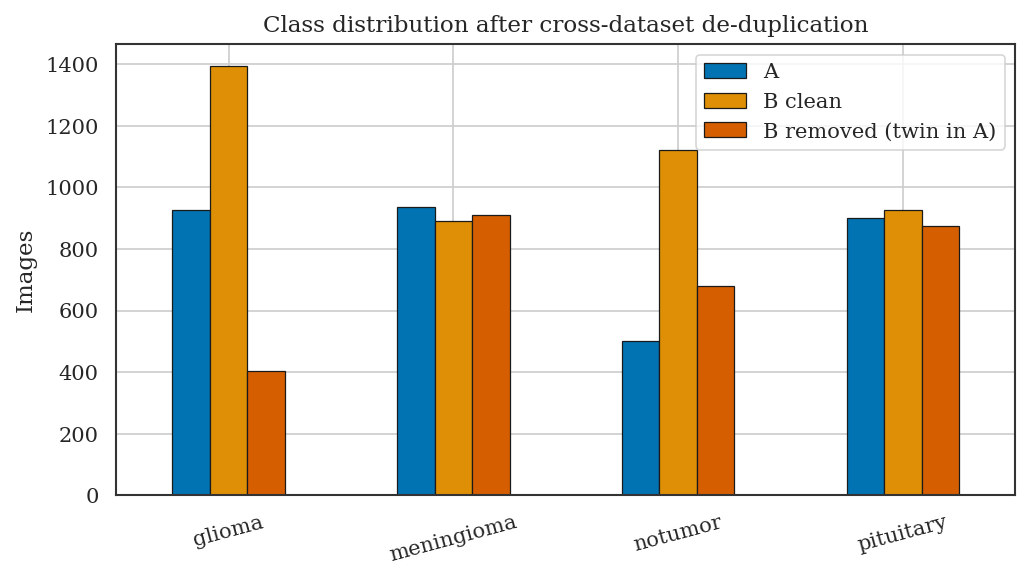

In [8]:
meta["group"] = -1; meta["split"] = "removed"
grp_stats = {}
for dom, idx in [(0, A_all), (1, B_keep)]:
    roots, npairs, nconf = dup_groups(idx, CFG.dup_corr)
    meta.loc[idx, "group"] = roots + dom * 10**6
    grp_stats[dom] = dict(images=len(idx), clusters=len(np.unique(roots)), largest_cluster=int(np.bincount(roots).max()), dup_pairs=npairs, label_conflicts=nconf)
    if grp_stats[dom]["largest_cluster"] > 0.05 * len(idx): print(f"WARNING: domain {dom} has a giant duplicate cluster ({grp_stats[dom]['largest_cluster']} images) — consider raising dup_corr")
    sg = StratifiedGroupKFold(n_splits=CFG.n_splits, shuffle=True, random_state=0)
    folds = list(sg.split(idx, Y[idx], groups=meta.group.values[idx]))
    sp = np.array(["train"] * len(idx), dtype=object); sp[folds[0][1]] = "test"; sp[folds[1][1]] = "val"
    meta.loc[idx, "split"] = sp
print(pd.DataFrame(grp_stats).rename(columns={0: "A", 1: "B_clean"}))

# no cluster may straddle splits
g = meta[meta.split != "removed"].groupby("group").split.nunique()
assert (g == 1).all(), "a duplicate cluster straddles train/val/test!"

def idxs(dom, split): return np.where((meta.domain == dom) & (meta.split == split))[0]
A_tr, A_va, A_te = idxs(0, "train"), idxs(0, "val"), idxs(0, "test")
B_tr, B_va, B_te = idxs(1, "train"), idxs(1, "val"), idxs(1, "test")
partner_split = meta.split.values[meta.nn_A_idx.values[B_dup].astype(int)] if len(B_dup) else np.array([])
B_leak = B_dup[partner_split == "train"] if len(B_dup) else B_dup    # removed B images whose A-twin is in A-TRAIN

print("\nSplit sizes:  A", (len(A_tr), len(A_va), len(A_te)), " B_clean", (len(B_tr), len(B_va), len(B_te)),
      " | B images that are twins of A-train:", len(B_leak))
print(pd.crosstab([meta.domain.map({0: "A", 1: "B"}), meta.split], meta.cls))
for nm, ix in [("A_tr", A_tr), ("A_te", A_te), ("B_tr", B_tr), ("B_te", B_te)]:
    if len(np.unique(Y[ix])) < 4: print(f"WARNING: {nm} is missing a class")

# ---- Figure 2 / audit table ----
audit = pd.DataFrame({
    "A": meta[meta.domain == 0].groupby("cls").size(),
    "B (all)": meta[meta.domain == 1].groupby("cls").size(),
    "B removed (twin in A)": meta[(meta.domain == 1) & ~meta.keep].groupby("cls").size(),
    "B clean": meta[(meta.domain == 1) & meta.keep].groupby("cls").size(),
}).fillna(0).astype(int)
print("\n", audit)
audit.to_csv(os.path.join(CFG.out_dir, "table1_dataset_audit.csv"))
ax = audit[["A", "B clean", "B removed (twin in A)"]].plot(kind="bar", figsize=(7, 4), color=[PAL[0], PAL[1], PAL[3]], edgecolor="k", lw=.6)
ax.set_ylabel("Images"); ax.set_xlabel(""); plt.xticks(rotation=15)
ax.set_title("Class distribution after cross-dataset de-duplication")
savefig("fig2_class_distribution.png")

## 6. Image preprocessing and acquisition-variation controls

Brain-cropping and per-image intensity normalization are applied consistently before model training. No metadata-only classifier or metadata shortcut probe is included.

In [9]:
# Metadata-only probe intentionally excluded from this study.

## 7. Model, GPU-side augmentation, training loop
* **Model:** ImageNet-pretrained ResNet18 → 512-d features → dropout → 4-way tumour head; a 2-way **domain head behind a Gradient Reversal Layer** (GRL) is used only by the adversarial arms.
* **Data live on the GPU as `uint8`** and are augmented on the GPU (flip, small affine, brightness/contrast; *strong* adds larger affine, gamma and noise), which makes each run fast enough to repeat over several seeds.
* **DANN schedule:** the reversal strength ramps with the standard `2/(1+exp(-10p)) - 1` curve up to `lambda_max`.
* **Selection:** the epoch with the best **source-domain validation macro-F1** is kept — no target labels are ever used for selection or tuning.

In [10]:
class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd; return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lambd * g, None

class Net(nn.Module):
    def __init__(self, n_cls=4, n_dom=2, pretrained=True, p=0.3):
        super().__init__()
        bb = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        bb.fc = nn.Identity(); self.bb = bb
        self.drop = nn.Dropout(p)
        self.cls = nn.Linear(512, n_cls)
        self.dom = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, n_dom))
    def forward(self, x, lambd=0.0):
        feat = self.bb(x); f = self.drop(feat)
        return self.cls(f), self.dom(GradReverse.apply(f, lambd)), feat

# ---------- data on device ----------
Xg   = torch.from_numpy(X).to(device)                                   # (N,S,S) uint8
Yg   = torch.from_numpy(Y.astype(np.int64)).to(device)
DOMg = torch.from_numpy(meta.domain.values.astype(np.int64)).to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def augment(x, strong):
    B, dev = x.size(0), x.device
    r = lambda: torch.rand(B, device=dev) * 2 - 1
    ang = r() * (20 if strong else 10) * math.pi / 180
    sc  = 1 + r() * (0.2 if strong else 0.1)
    tx, ty = r() * (0.10 if strong else 0.05), r() * (0.10 if strong else 0.05)
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="zeros", align_corners=False)
    ct = 1 + torch.rand(B, 1, 1, 1, device=dev).mul(2).sub(1) * (0.4 if strong else 0.2)
    br = (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * (0.15 if strong else 0.10)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * ct + m + br
    if strong:
        x = x.clamp(0, 1) ** torch.exp((torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.4)
        x = x + torch.randn_like(x) * 0.02
    return x.clamp(0, 1)

def to_input(xb, train=False, strong=False):
    x = xb.float().div(255).unsqueeze(1)
    if train: x = augment(x, strong)
    return (x.expand(-1, 3, -1, -1) - MEAN) / STD

def autocast(): return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)

@torch.no_grad()
def predict(model, idx, bs=256):
    model.eval(); L, Fe = [], []
    for s in range(0, len(idx), bs):
        it = torch.from_numpy(idx[s:s + bs]).to(device)
        with autocast(): lg, _, ft = model(to_input(Xg[it]), 0.0)
        L.append(lg.float().cpu()); Fe.append(ft.float().cpu())
    return torch.cat(L).numpy(), torch.cat(Fe).numpy()

def train_run(exp, seed):
    set_seed(seed); rng = np.random.RandomState(seed)
    model = Net(pretrained=CFG.pretrained).to(device)
    lab, unl, val = exp["lab"], exp["unl"], exp["val"]
    use_unl = unl is not None and len(unl) > 0
    bs = CFG.batch_size; steps = max(1, len(lab) // bs); total = CFG.epochs * steps
    cnt = np.bincount(Y[lab], minlength=4)
    w = torch.tensor(cnt.sum() / (4 * np.clip(cnt, 1, None)), dtype=torch.float32, device=device)
    ce_c, ce_d = nn.CrossEntropyLoss(weight=w), nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.epochs)
    try: scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    unl_perm, ptr = (rng.permutation(unl), 0) if use_unl else (None, 0)
    best_f1, best_state, hist, it_n = -1.0, None, [], 0

    for ep in range(CFG.epochs):
        model.train(); perm = rng.permutation(lab)
        sc = sd = sa = torch.zeros((), device=device)
        for s in range(steps):
            b = perm[s * bs:(s + 1) * bs]
            if use_unl:
                if ptr + bs > len(unl_perm): unl_perm, ptr = rng.permutation(unl), 0
                allb = np.concatenate([b, unl_perm[ptr:ptr + bs]]); ptr += bs
            else:
                allb = b
            it = torch.from_numpy(allb).to(device)
            x = to_input(Xg[it], train=True, strong=exp["strong"])
            y, d = Yg[it[:len(b)]], DOMg[it]
            lam = CFG.lambda_max * (2 / (1 + math.exp(-10 * it_n / total)) - 1) if exp["adv"] else 0.0
            with autocast():
                cl, dl, _ = model(x, lam)
                lc = ce_c(cl[:len(b)].float(), y); loss = lc
                if exp["adv"]:
                    ld = ce_d(dl.float(), d); loss = loss + ld
                    sd = sd + ld.detach(); sa = sa + (dl.argmax(1) == d).float().mean()
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            sc = sc + lc.detach(); it_n += 1
        sched.step()
        lg, _ = predict(model, val)
        f1 = f1_score(Y[val], lg.argmax(1), average="macro")
        hist.append(dict(epoch=ep + 1, loss_cls=float(sc) / steps, loss_dom=float(sd) / steps,
                         dom_acc=float(sa) / steps, val_f1=f1))
        if f1 > best_f1:
            best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, hist

## 8. Experimental arms
All arms use the same architecture, optimizer, epochs and seeds. What differs is *only* what data/labels the model may see:

| Arm | Labelled data | Unlabelled data | Adversary | Purpose |
|---|---|---|---|---|
| **ERM \| A** (and **B**) | source train | – | no | plain source-only baseline |
| **ERM+Aug \| A** (and **B**) | source train | – | no | *strong* baseline: heavy augmentation (a cheap competitor to DANN) |
| **DANN-UDA \| A>B** (and **B>A**) | source train | **target train, labels never used** | yes | the actual domain-adaptation claim |
| **Pooled-ERM \| A+B** | both, with labels | – | no | oracle / "just add the data" control |
| **Pooled-DANN \| A+B** | both, with labels | – | yes | does the adversary help *beyond* pooling? (v1's confound) |

Evaluation sets: `A_test`, `B_test` (both never used in training or selection), and `B_leaked` — the B images that were removed as twins of A-train images, kept only to **quantify how much leakage would have inflated the result**.

In [11]:
rng0 = np.random.RandomState(123)
pA = rng0.permutation(A_tr)[:CFG.probe_cap]; pB = rng0.permutation(B_tr)[:CFG.probe_cap]   # train-side samples for the domain probe
EVAL = {"A_test": A_te, "B_test": B_te, "B_leaked": B_leak, "A_probe_tr": pA, "B_probe_tr": pB}
EVAL = {k: v for k, v in EVAL.items() if len(v) > 0}
EVAL_ALL = np.concatenate(list(EVAL.values()))
OFFS, s0 = {}, 0
for k, v in EVAL.items(): OFFS[k] = (s0, s0 + len(v)); s0 += len(v)

cat = lambda a, b: np.concatenate([a, b])
def E(id_, lab, val, unl=None, adv=False, strong=False, keep=False):
    return dict(id=id_, lab=lab, val=val, unl=unl, adv=adv, strong=strong, keep=keep)

EXPS = [
    E("ERM|A",           A_tr, A_va, keep=True),
    E("ERM+Aug|A",       A_tr, A_va, strong=True),
    E("DANN-UDA|A>B",    A_tr, A_va, unl=B_tr, adv=True, keep=True),
    E("ERM|B",           B_tr, B_va, keep=True),
    E("ERM+Aug|B",       B_tr, B_va, strong=True),
    E("DANN-UDA|B>A",    B_tr, B_va, unl=A_tr, adv=True, keep=True),
    E("Pooled-ERM|A+B",  cat(A_tr, B_tr), cat(A_va, B_va)),
    E("Pooled-DANN|A+B", cat(A_tr, B_tr), cat(A_va, B_va), adv=True),
]
safe = lambda s: re.sub(r"[^A-Za-z0-9]+", "_", s)
RUN_DIR = os.path.join(CFG.out_dir, f"runs_{SIG}_e{CFG.epochs}_r{int(CFG.dup_corr*100)}"); os.makedirs(RUN_DIR, exist_ok=True)
print(f"{len(EXPS)} arms x {len(CFG.seeds)} seeds = {len(EXPS)*len(CFG.seeds)} trainings | run cache: {RUN_DIR}")

8 arms x 3 seeds = 24 trainings | run cache: /kaggle/working/outputs/runs_224_1_1_10464_0a2d687c_e15_r90


## 9. Run everything
Each finished run is written to disk immediately; re-running this cell after a disconnect resumes where it stopped.

In [12]:
RUNS = {}
for seed in CFG.seeds:
    for exp in EXPS:
        key = (exp["id"], seed); fn = os.path.join(RUN_DIR, f"{safe(exp['id'])}_s{seed}.pkl")
        if os.path.exists(fn):
            RUNS[key] = pickle.load(open(fn, "rb")); print(f"[cached] {key}"); continue
        t0 = time.time()
        model, hist = train_run(exp, seed)
        lg, ft = predict(model, EVAL_ALL)
        out = dict(logits={k: lg[a:b] for k, (a, b) in OFFS.items()},
                   feats={k: ft[a:b] for k, (a, b) in OFFS.items()} if exp["keep"] else {},
                   hist=hist,
                   state={k: v.cpu() for k, v in model.state_dict().items()} if (exp["keep"] and seed == CFG.seeds[0]) else None)
        pickle.dump(out, open(fn, "wb")); RUNS[key] = out
        h = hist[-1]; best = max(x["val_f1"] for x in hist)
        print(f"[done] {exp['id']:<18} seed={seed} | best val-F1={best:.4f} | "
              f"A_test acc={accuracy_score(Y[A_te], out['logits']['A_test'].argmax(1)):.4f} "
              f"B_test acc={accuracy_score(Y[B_te], out['logits']['B_test'].argmax(1)):.4f} | "
              f"dom-acc(last ep)={h['dom_acc']:.2f} | {time.time()-t0:.0f}s")
        del model
        if device.type == "cuda": torch.cuda.empty_cache()

[done] ERM|A              seed=0 | best val-F1=0.9071 | A_test acc=0.9419 B_test acc=0.9746 | dom-acc(last ep)=0.00 | 66s
[done] ERM+Aug|A          seed=0 | best val-F1=0.8607 | A_test acc=0.8802 B_test acc=0.9198 | dom-acc(last ep)=0.00 | 64s
[done] DANN-UDA|A>B       seed=0 | best val-F1=0.9061 | A_test acc=0.9310 B_test acc=0.9545 | dom-acc(last ep)=0.45 | 117s
[done] ERM|B              seed=0 | best val-F1=0.9879 | A_test acc=0.9020 B_test acc=0.9826 | dom-acc(last ep)=0.00 | 85s
[done] ERM+Aug|B          seed=0 | best val-F1=0.9869 | A_test acc=0.8748 B_test acc=0.9813 | dom-acc(last ep)=0.00 | 86s
[done] DANN-UDA|B>A       seed=0 | best val-F1=0.9852 | A_test acc=0.8584 B_test acc=0.9746 | dom-acc(last ep)=0.46 | 156s
[done] Pooled-ERM|A+B     seed=0 | best val-F1=0.9681 | A_test acc=0.9474 B_test acc=0.9973 | dom-acc(last ep)=0.00 | 147s
[done] Pooled-DANN|A+B    seed=0 | best val-F1=0.9698 | A_test acc=0.9619 B_test acc=0.9987 | dom-acc(last ep)=0.45 | 148s
[done] ERM|A        

## 10. Main results with proper statistics
* **Accuracy** = mean over seeds. **95% CI** = bootstrap over *test images* (of the seed-averaged accuracy). **±sd** = spread across seeds (init/order variance).
* Everything is on test sets that were never used for training, tuning or model selection.

In [13]:
rng_b = np.random.default_rng(0)

def correct(exp_id, name):
    y = Y[EVAL[name]]
    return np.stack([RUNS[(exp_id, s)]["logits"][name].argmax(1) == y for s in CFG.seeds])

def macro_f1(exp_id, name):
    y = Y[EVAL[name]]
    return np.array([f1_score(y, RUNS[(exp_id, s)]["logits"][name].argmax(1), average="macro") for s in CFG.seeds])

def boot(C, n=None):
    n = n or CFG.n_boot; m = C.shape[1]; v = np.empty(n)
    for b in range(n): v[b] = C[:, rng_b.integers(0, m, m)].mean()
    lo, hi = np.percentile(v, [2.5, 97.5]); return C.mean(), lo, hi

def paired_boot(C1, C2, n=None):
    n = n or CFG.n_boot; D = C1.astype(float) - C2.astype(float); m = D.shape[1]; v = np.empty(n)
    for b in range(n): v[b] = D[:, rng_b.integers(0, m, m)].mean()
    lo, hi = np.percentile(v, [2.5, 97.5]); p = min(1.0, 2 * min((v <= 0).mean(), (v >= 0).mean()))
    return D.mean(), lo, hi, p

rows = []
for exp in EXPS:
    for name in ["A_test", "B_test"]:
        C = correct(exp["id"], name); m, lo, hi = boot(C)
        sd = C.mean(1).std(ddof=1) if len(CFG.seeds) > 1 else np.nan
        rows.append(dict(model=exp["id"], eval=name, acc=m, lo=lo, hi=hi, sd=sd, f1=macro_f1(exp["id"], name).mean()))
main_df = pd.DataFrame(rows)
main_df.to_csv(os.path.join(CFG.out_dir, "table2_main_results.csv"), index=False)

def fmt(r): return f"{r.acc:.3f} [{r.lo:.3f}, {r.hi:.3f}] ±{r.sd:.3f} | F1 {r.f1:.3f}"
disp = main_df.assign(txt=main_df.apply(fmt, axis=1)).pivot(index="model", columns="eval", values="txt").loc[[e["id"] for e in EXPS]]
pd.set_option("display.max_colwidth", 80); print("Table 2. accuracy [95% CI] ±seed-sd | macro-F1\n"); print(disp.to_string())

# domain gap for source-trained models (in-domain minus cross-domain accuracy)
gap = []
for eid, src, tgt in [("ERM|A", "A_test", "B_test"), ("ERM+Aug|A", "A_test", "B_test"), ("DANN-UDA|A>B", "A_test", "B_test"),
                      ("ERM|B", "B_test", "A_test"), ("ERM+Aug|B", "B_test", "A_test"), ("DANN-UDA|B>A", "B_test", "A_test")]:
    a = main_df[(main_df.model == eid) & (main_df["eval"] == src)].acc.item(); b = main_df[(main_df.model == eid) & (main_df["eval"] == tgt)].acc.item()
    gap.append(dict(model=eid, in_domain=a, cross_domain=b, gap=a - b))
gap_df = pd.DataFrame(gap); print("\nDomain gap (in-domain acc − cross-domain acc); positive = accuracy drops under shift\n"); print(gap_df.round(4).to_string(index=False))
gap_df.to_csv(os.path.join(CFG.out_dir, "table3_domain_gap.csv"), index=False)

Table 2. accuracy [95% CI] ±seed-sd | macro-F1

eval                                             A_test                                  B_test
model                                                                                          
ERM|A            0.932 [0.913, 0.950] ±0.014 | F1 0.934  0.975 [0.965, 0.985] ±0.003 | F1 0.974
ERM+Aug|A        0.903 [0.883, 0.923] ±0.020 | F1 0.906  0.941 [0.926, 0.954] ±0.021 | F1 0.940
DANN-UDA|A>B     0.926 [0.907, 0.945] ±0.008 | F1 0.926  0.952 [0.940, 0.964] ±0.023 | F1 0.949
ERM|B            0.894 [0.869, 0.917] ±0.007 | F1 0.877  0.984 [0.976, 0.990] ±0.003 | F1 0.981
ERM+Aug|B        0.881 [0.857, 0.904] ±0.006 | F1 0.860  0.976 [0.967, 0.984] ±0.006 | F1 0.975
DANN-UDA|B>A     0.861 [0.834, 0.887] ±0.004 | F1 0.847  0.980 [0.971, 0.988] ±0.005 | F1 0.977
Pooled-ERM|A+B   0.949 [0.931, 0.964] ±0.002 | F1 0.949  0.995 [0.991, 0.998] ±0.004 | F1 0.994
Pooled-DANN|A+B  0.961 [0.946, 0.975] ±0.002 | F1 0.961  0.996 [0.994, 0.999] ±0.004 | F

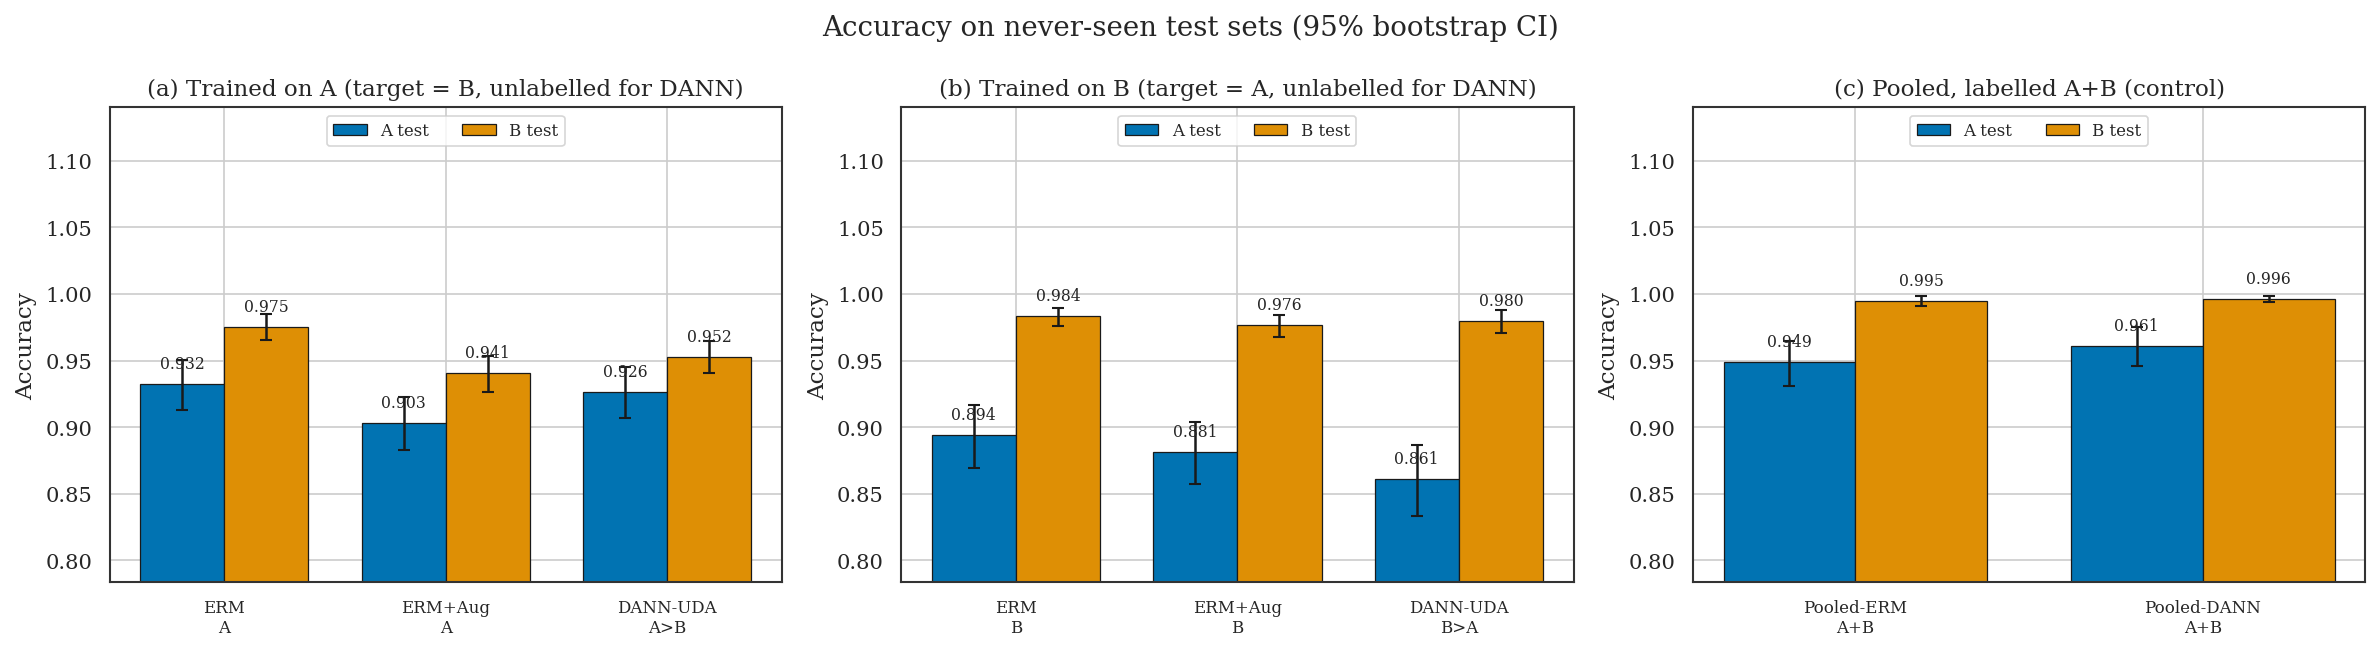

In [14]:
# ---- Figure 4: main results ----
def panel(ax, ids, title, names=("A_test", "B_test"), colors=(PAL[0], PAL[1])):
    w = 0.38; x = np.arange(len(ids))
    for j, nm in enumerate(names):
        d = main_df[main_df["eval"] == nm].set_index("model").loc[ids]
        ax.bar(x + (j - .5) * w, d.acc, w, yerr=[d.acc - d.lo, d.hi - d.acc], capsize=3, color=colors[j], edgecolor="k", lw=.6, label=nm.replace("_", " "))
        for xi, v in zip(x + (j - .5) * w, d.acc): ax.text(xi, min(1.0, v) + .012, f"{v:.3f}", ha="center", fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels([i.replace("|", "\n") for i in ids], fontsize=8)
    lo = max(0.0, main_df.lo.min() - 0.05); ax.set_ylim(lo, 1.14); ax.set_ylabel("Accuracy"); ax.set_title(title); ax.legend(fontsize=8, loc="upper center", ncol=2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
panel(axes[0], ["ERM|A", "ERM+Aug|A", "DANN-UDA|A>B"], "(a) Trained on A (target = B, unlabelled for DANN)")
panel(axes[1], ["ERM|B", "ERM+Aug|B", "DANN-UDA|B>A"], "(b) Trained on B (target = A, unlabelled for DANN)")
panel(axes[2], ["Pooled-ERM|A+B", "Pooled-DANN|A+B"], "(c) Pooled, labelled A+B (control)")
plt.suptitle("Accuracy on never-seen test sets (95% bootstrap CI)")
savefig("fig4_main_results.png")

### 10b. Paired significance tests
Each row asks one specific question. `diff` = (first − second) accuracy on the *same* test images, averaged over seeds; the CI/p-value come from a **paired bootstrap** over test images. A CI that includes 0 means **no reliable difference**.

In [15]:
COMPS = [
    ("DANN-UDA|A>B", "ERM|A",        "B_test", "Does UDA beat source-only, A→B?"),
    ("DANN-UDA|A>B", "ERM+Aug|A",    "B_test", "Does UDA beat *strong-aug* source-only, A→B?"),
    ("DANN-UDA|B>A", "ERM|B",        "A_test", "Does UDA beat source-only, B→A?"),
    ("DANN-UDA|B>A", "ERM+Aug|B",    "A_test", "Does UDA beat *strong-aug* source-only, B→A?"),
    ("ERM+Aug|A",    "ERM|A",        "B_test", "Do strong augmentations alone help, A→B?"),
    ("ERM+Aug|B",    "ERM|B",        "A_test", "Do strong augmentations alone help, B→A?"),
    ("Pooled-DANN|A+B", "Pooled-ERM|A+B", "A_test", "Adversary vs. no adversary when data are pooled (A)"),
    ("Pooled-DANN|A+B", "Pooled-ERM|A+B", "B_test", "Adversary vs. no adversary when data are pooled (B)"),
]
crow = []
for a, b, name, q in COMPS:
    d, lo, hi, p = paired_boot(correct(a, name), correct(b, name))
    per_seed = ", ".join(f"{x:+.3f}" for x in (correct(a, name).mean(1) - correct(b, name).mean(1)))
    verdict = "improves" if lo > 0 else ("hurts" if hi < 0 else "no reliable difference")
    crow.append(dict(question=q, test_set=name, diff=d, ci_lo=lo, ci_hi=hi, p=p, per_seed_diff=per_seed, verdict=verdict))
comp_df = pd.DataFrame(crow); comp_df.to_csv(os.path.join(CFG.out_dir, "table4_paired_tests.csv"), index=False)
print(comp_df.assign(diff=comp_df["diff"].map("{:+.4f}".format), ci=comp_df.apply(lambda r: f"[{r.ci_lo:+.4f}, {r.ci_hi:+.4f}]", axis=1),
                     p=comp_df.p.map("{:.3f}".format))[["question", "test_set", "diff", "ci", "p", "per_seed_diff", "verdict"]].to_string(index=False))

                                           question test_set    diff                 ci     p          per_seed_diff                verdict
                    Does UDA beat source-only, A→B?   B_test -0.0232 [-0.0321, -0.0147] 0.000 -0.020, -0.004, -0.045                  hurts
       Does UDA beat *strong-aug* source-only, A→B?   B_test +0.0116 [-0.0013, +0.0245] 0.097 +0.035, +0.033, -0.033 no reliable difference
                    Does UDA beat source-only, B→A?   A_test -0.0333 [-0.0538, -0.0121] 0.002 -0.044, -0.033, -0.024                  hurts
       Does UDA beat *strong-aug* source-only, B→A?   A_test -0.0206 [-0.0393, -0.0018] 0.033 -0.016, -0.025, -0.020                  hurts
           Do strong augmentations alone help, A→B?   B_test -0.0348 [-0.0463, -0.0236] 0.000 -0.055, -0.037, -0.012                  hurts
           Do strong augmentations alone help, B→A?   A_test -0.0127 [-0.0272, +0.0006] 0.069 -0.027, -0.007, -0.004 no reliable difference
Adversary vs. no adv

### 10c. How much would the leakage in v1 have inflated the numbers?
`B_leaked` = images of B that were **removed** because they are near-twins of an A-*train* image. A model trained on A should look far better on these than on the clean `B_test` — if it does, that gap is pure leakage, and it is exactly what inflated v1's "held-out domain" accuracy.

       model     eval    acc     lo     hi    n
       ERM|A   B_test 0.9755 0.9652 0.9849  748
       ERM|A B_leaked 0.9954 0.9932 0.9974 1900
   ERM+Aug|A   B_test 0.9407 0.9269 0.9537  748
   ERM+Aug|A B_leaked 0.9626 0.9565 0.9684 1900
DANN-UDA|A>B   B_test 0.9523 0.9403 0.9639  748
DANN-UDA|A>B B_leaked 0.9935 0.9911 0.9954 1900


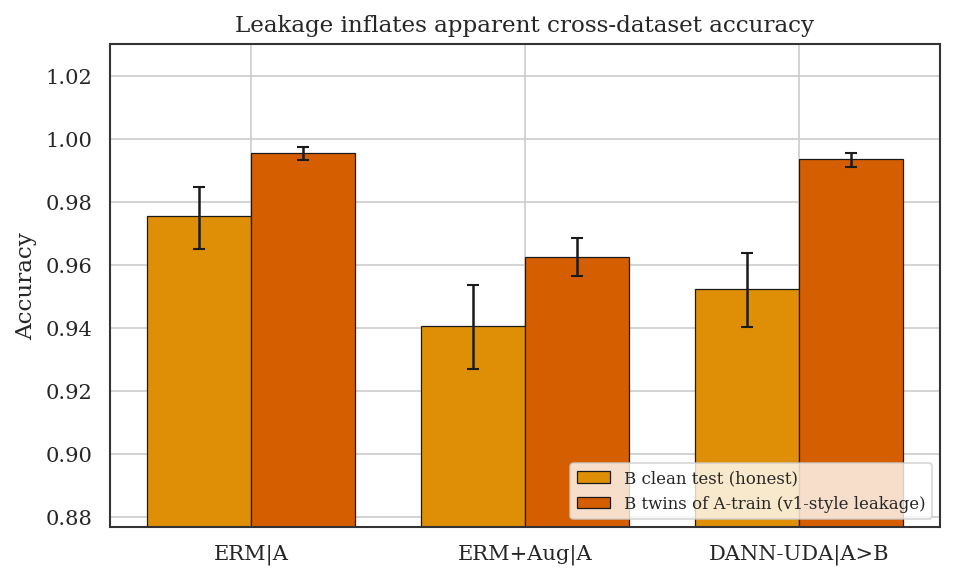

In [16]:
if "B_leaked" in EVAL:
    rows = []
    for eid in ["ERM|A", "ERM+Aug|A", "DANN-UDA|A>B"]:
        for nm in ["B_test", "B_leaked"]:
            m, lo, hi = boot(correct(eid, nm)); rows.append(dict(model=eid, eval=nm, acc=m, lo=lo, hi=hi, n=len(EVAL[nm])))
    leak_df = pd.DataFrame(rows); print(leak_df.round(4).to_string(index=False))
    leak_df.to_csv(os.path.join(CFG.out_dir, "table5_leakage_inflation.csv"), index=False)
    fig, ax = plt.subplots(figsize=(6.5, 4)); ids = ["ERM|A", "ERM+Aug|A", "DANN-UDA|A>B"]; x = np.arange(3); w = .38
    for j, (nm, col, lab) in enumerate([("B_test", PAL[1], "B clean test (honest)"), ("B_leaked", PAL[3], "B twins of A-train (v1-style leakage)")]):
        d = leak_df[leak_df["eval"] == nm].set_index("model").loc[ids]
        ax.bar(x + (j - .5) * w, d.acc, w, yerr=[d.acc - d.lo, d.hi - d.acc], capsize=3, color=col, edgecolor="k", lw=.6, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(ids); ax.set_ylabel("Accuracy"); ax.set_ylim(max(0, leak_df.lo.min() - .05), 1.03); ax.legend(fontsize=8, loc="lower right")
    ax.set_title("Leakage inflates apparent cross-dataset accuracy")
    savefig("fig5_leakage_inflation.png")
else:
    print("No removed near-duplicates with a twin in A-train -> nothing to compare (the datasets did not overlap at this threshold).")

## 11. Did the adversary actually remove domain information? — quantitative probe + t-SNE
A logistic-regression probe is trained on frozen features of **train** images (A vs. B) and tested on **held-out test** images. Accuracy near 50% means the domain is not linearly decodable (features are domain-invariant); near 100% means the network still "knows" which dataset an image came from. Lower is *more invariant* — but note that invariance alone does not guarantee better classification, which is why §10 measures accuracy directly.

       model  domain_probe_acc_mean     sd
       ERM|A                 0.6727 0.0070
DANN-UDA|A>B                 0.6649 0.0047
       ERM|B                 0.6906 0.0120
DANN-UDA|B>A                 0.6845 0.0249


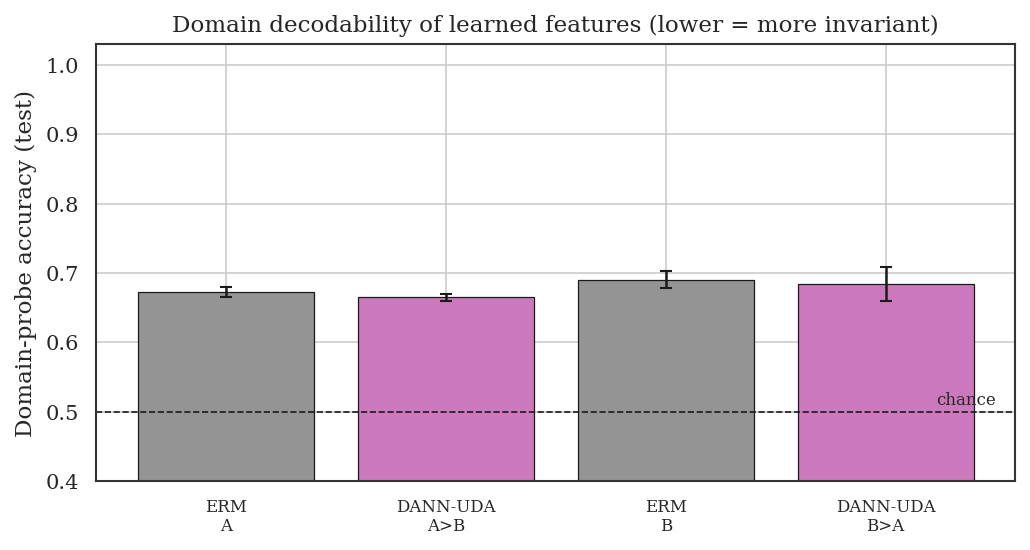

In [17]:
def domain_probe(exp_id, seed):
    Fd = RUNS[(exp_id, seed)]["feats"]; r = np.random.RandomState(seed)
    Xtr = np.vstack([Fd["A_probe_tr"], Fd["B_probe_tr"]]); ytr = np.r_[np.zeros(len(Fd["A_probe_tr"])), np.ones(len(Fd["B_probe_tr"]))]
    n = min(len(Fd["A_test"]), len(Fd["B_test"]))
    Xte = np.vstack([Fd["A_test"][r.permutation(len(Fd["A_test"]))[:n]], Fd["B_test"][r.permutation(len(Fd["B_test"]))[:n]]]); yte = np.r_[np.zeros(n), np.ones(n)]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1)).fit(Xtr, ytr)
    return clf.score(Xte, yte)

probe_ids = [e["id"] for e in EXPS if e["keep"]]
probe = {eid: np.array([domain_probe(eid, s) for s in CFG.seeds]) for eid in probe_ids}
probe_df = pd.DataFrame({"model": probe_ids, "domain_probe_acc_mean": [probe[e].mean() for e in probe_ids],
                         "sd": [probe[e].std(ddof=1) if len(CFG.seeds) > 1 else np.nan for e in probe_ids]})
print(probe_df.round(4).to_string(index=False)); probe_df.to_csv(os.path.join(CFG.out_dir, "table6_domain_probe.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(range(len(probe_ids)), probe_df.domain_probe_acc_mean, yerr=probe_df.sd.fillna(0), capsize=3, color=[PAL[4] if "DANN" in e else PAL[7] for e in probe_ids], edgecolor="k", lw=.6)
ax.axhline(.5, ls="--", c="k", lw=.8); ax.text(len(probe_ids) - .5, .51, "chance", ha="right", fontsize=8)
ax.set_xticks(range(len(probe_ids))); ax.set_xticklabels([e.replace("|", "\n") for e in probe_ids], fontsize=8)
ax.set_ylabel("Domain-probe accuracy (test)"); ax.set_ylim(.4, 1.03); ax.set_title("Domain decodability of learned features (lower = more invariant)")
savefig("fig6_domain_probe.png")

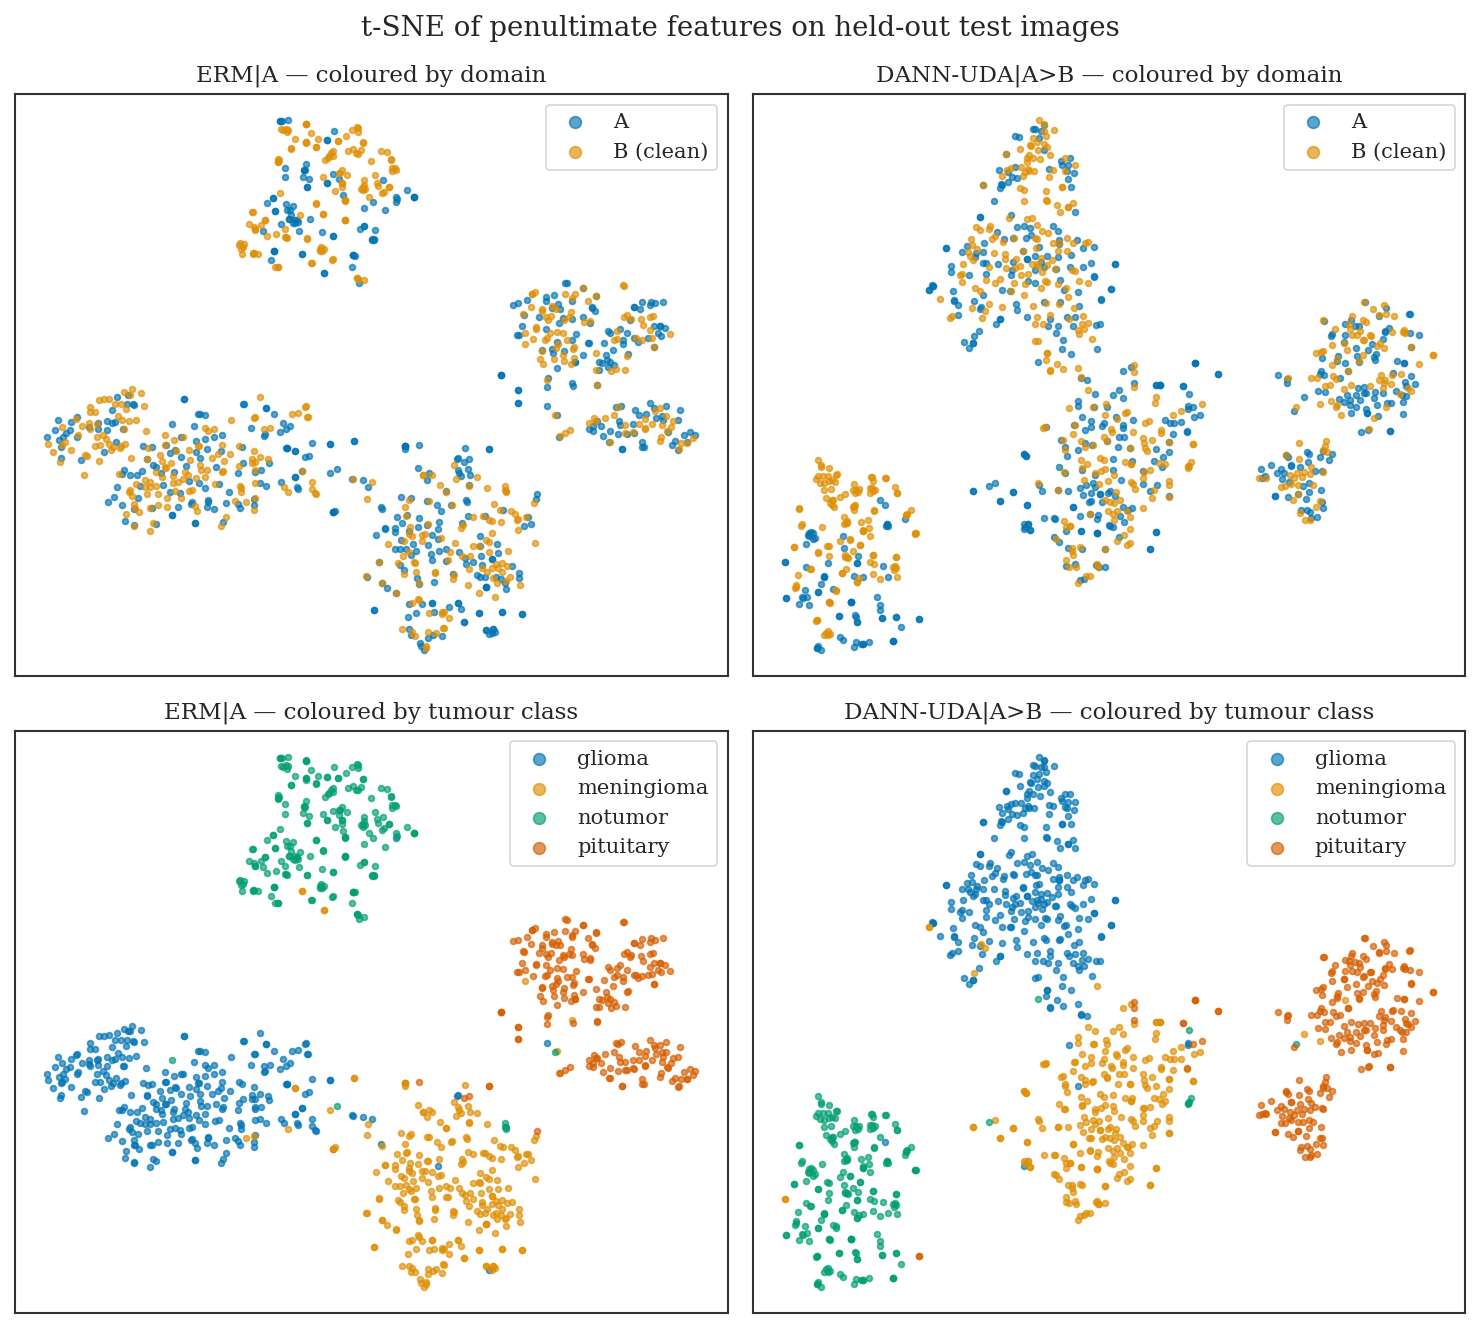

In [18]:
# ---- Figure 7: t-SNE, source-only vs DANN (same points, seed 0) ----
s0_ = CFG.seeds[0]; r = np.random.RandomState(0)
def sub(a, n): return a[r.permutation(len(a))[:n]]
nA = min(500, len(EVAL["A_test"])); nB = min(500, len(EVAL["B_test"]))
ia = r.permutation(len(EVAL["A_test"]))[:nA]; ib = r.permutation(len(EVAL["B_test"]))[:nB]
ycls = np.r_[Y[EVAL["A_test"]][ia], Y[EVAL["B_test"]][ib]]; ydom = np.r_[np.zeros(nA), np.ones(nB)]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for j, eid in enumerate(["ERM|A", "DANN-UDA|A>B"]):
    Fd = RUNS[(eid, s0_)]["feats"]; Z = np.vstack([Fd["A_test"][ia], Fd["B_test"][ib]])
    emb = TSNE(n_components=2, perplexity=max(5, min(30, len(Z) // 4)), init="pca", learning_rate="auto", random_state=0).fit_transform(Z)
    for d, nm, col in [(0, "A", PAL[0]), (1, "B (clean)", PAL[1])]:
        axes[0, j].scatter(*emb[ydom == d].T, s=8, alpha=.65, color=col, label=nm)
    axes[0, j].set_title(f"{eid} — coloured by domain"); axes[0, j].legend(markerscale=2)
    for c, cn in enumerate(CFG.class_names): axes[1, j].scatter(*emb[ycls == c].T, s=8, alpha=.65, color=PAL[c], label=cn)
    axes[1, j].set_title(f"{eid} — coloured by tumour class"); axes[1, j].legend(markerscale=2)
    for a in axes[:, j]: a.set_xticks([]); a.set_yticks([])
plt.suptitle("t-SNE of penultimate features on held-out test images")
savefig("fig7_tsne.png")

## 12. Uncertainty (MC-dropout) on the *whole* test sets
Dropout on the feature vector is kept active for `mc_passes` stochastic passes over frozen backbone features (exactly equivalent to full MC-dropout for this head, and much cheaper). We report **calibration (ECE)**, how well uncertainty **detects errors (AUROC)**, and **risk–coverage** (error rate if the model abstains on its most uncertain cases). Cases with no errors produce `NaN` instead of an empty plot.

       model test_set    acc    ECE  n_errors  AUROC_entropy  AUROC_mutual_info   AURC
       ERM|A   A_test 0.9419 0.0351        32         0.8820             0.8704 0.0095
       ERM|A   B_test 0.9733 0.0103        20         0.9044             0.9046 0.0035
DANN-UDA|A>B   A_test 0.9310 0.0446        38         0.8200             0.8228 0.0192
DANN-UDA|A>B   B_test 0.9545 0.0247        34         0.8515             0.8615 0.0099


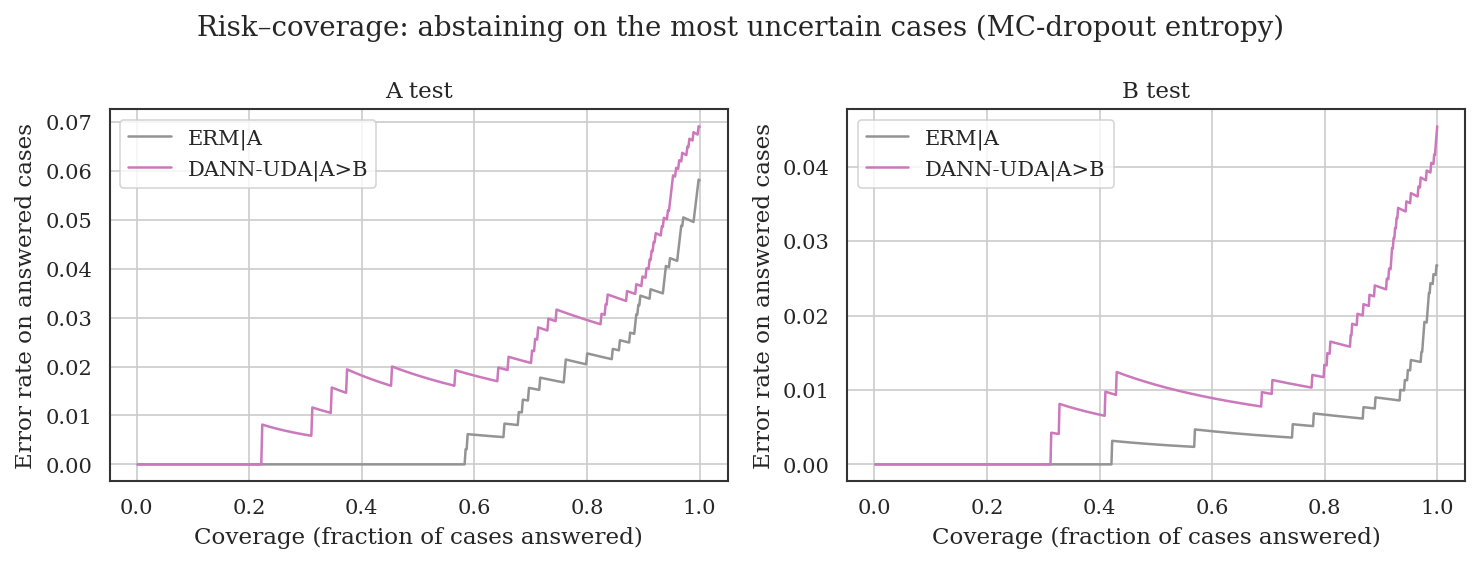

In [19]:
def load_model(exp_id):
    m = Net(pretrained=False).to(device); m.load_state_dict(RUNS[(exp_id, CFG.seeds[0])]["state"]); return m.eval()

@torch.no_grad()
def mc_probs(model, feats, passes):
    f = torch.from_numpy(feats).to(device); model.eval(); model.drop.train()
    P = torch.stack([F.softmax(model.cls(model.drop(f)), 1) for _ in range(passes)]).cpu().numpy(); model.drop.eval(); return P

def ece_score(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1); acc = (pred == y); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e

def risk_coverage(unc, err):
    o = np.argsort(unc); cum = np.cumsum(err[o]) / (np.arange(len(o)) + 1); return (np.arange(len(o)) + 1) / len(o), cum

unc_rows, rc = [], {}
for eid in ["ERM|A", "DANN-UDA|A>B"]:
    model = load_model(eid)
    for nm in ["A_test", "B_test"]:
        Pm = mc_probs(model, RUNS[(eid, CFG.seeds[0])]["feats"][nm], CFG.mc_passes); pm = Pm.mean(0); y = Y[EVAL[nm]]
        H = -(pm * np.log(pm + 1e-12)).sum(1); EH = (-(Pm * np.log(Pm + 1e-12)).sum(2)).mean(0); MI = H - EH
        err = (pm.argmax(1) != y).astype(float); ok = 0 < err.sum() < len(err)
        cov, risk = risk_coverage(H, err); rc[(eid, nm)] = (cov, risk)
        unc_rows.append(dict(model=eid, test_set=nm, acc=1 - err.mean(), ECE=ece_score(pm, y), n_errors=int(err.sum()),
                             AUROC_entropy=roc_auc_score(err, H) if ok else np.nan, AUROC_mutual_info=roc_auc_score(err, MI) if ok else np.nan,
                             AURC=risk.mean()))
unc_df = pd.DataFrame(unc_rows); print(unc_df.round(4).to_string(index=False)); unc_df.to_csv(os.path.join(CFG.out_dir, "table7_uncertainty.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, nm in zip(ax, ["A_test", "B_test"]):
    for eid, col in [("ERM|A", PAL[7]), ("DANN-UDA|A>B", PAL[4])]:
        cov, risk = rc[(eid, nm)]; a.plot(cov, risk, label=eid, color=col)
    a.set_xlabel("Coverage (fraction of cases answered)"); a.set_ylabel("Error rate on answered cases"); a.set_title(nm.replace("_", " ")); a.legend()
plt.suptitle("Risk–coverage: abstaining on the most uncertain cases (MC-dropout entropy)")
savefig("fig8_risk_coverage.png")

## 13. Grad-CAM (explainability)
Own implementation (hooks on the last ResNet block), so there is no extra dependency. Columns are **target-domain (B) test cases where the source-only model is wrong and DANN is right** (padded with random cases if fewer exist). Look for whether the source-only model attends to the skull/background or scanner artefacts while DANN attends to the lesion — but treat this as illustration, not proof.

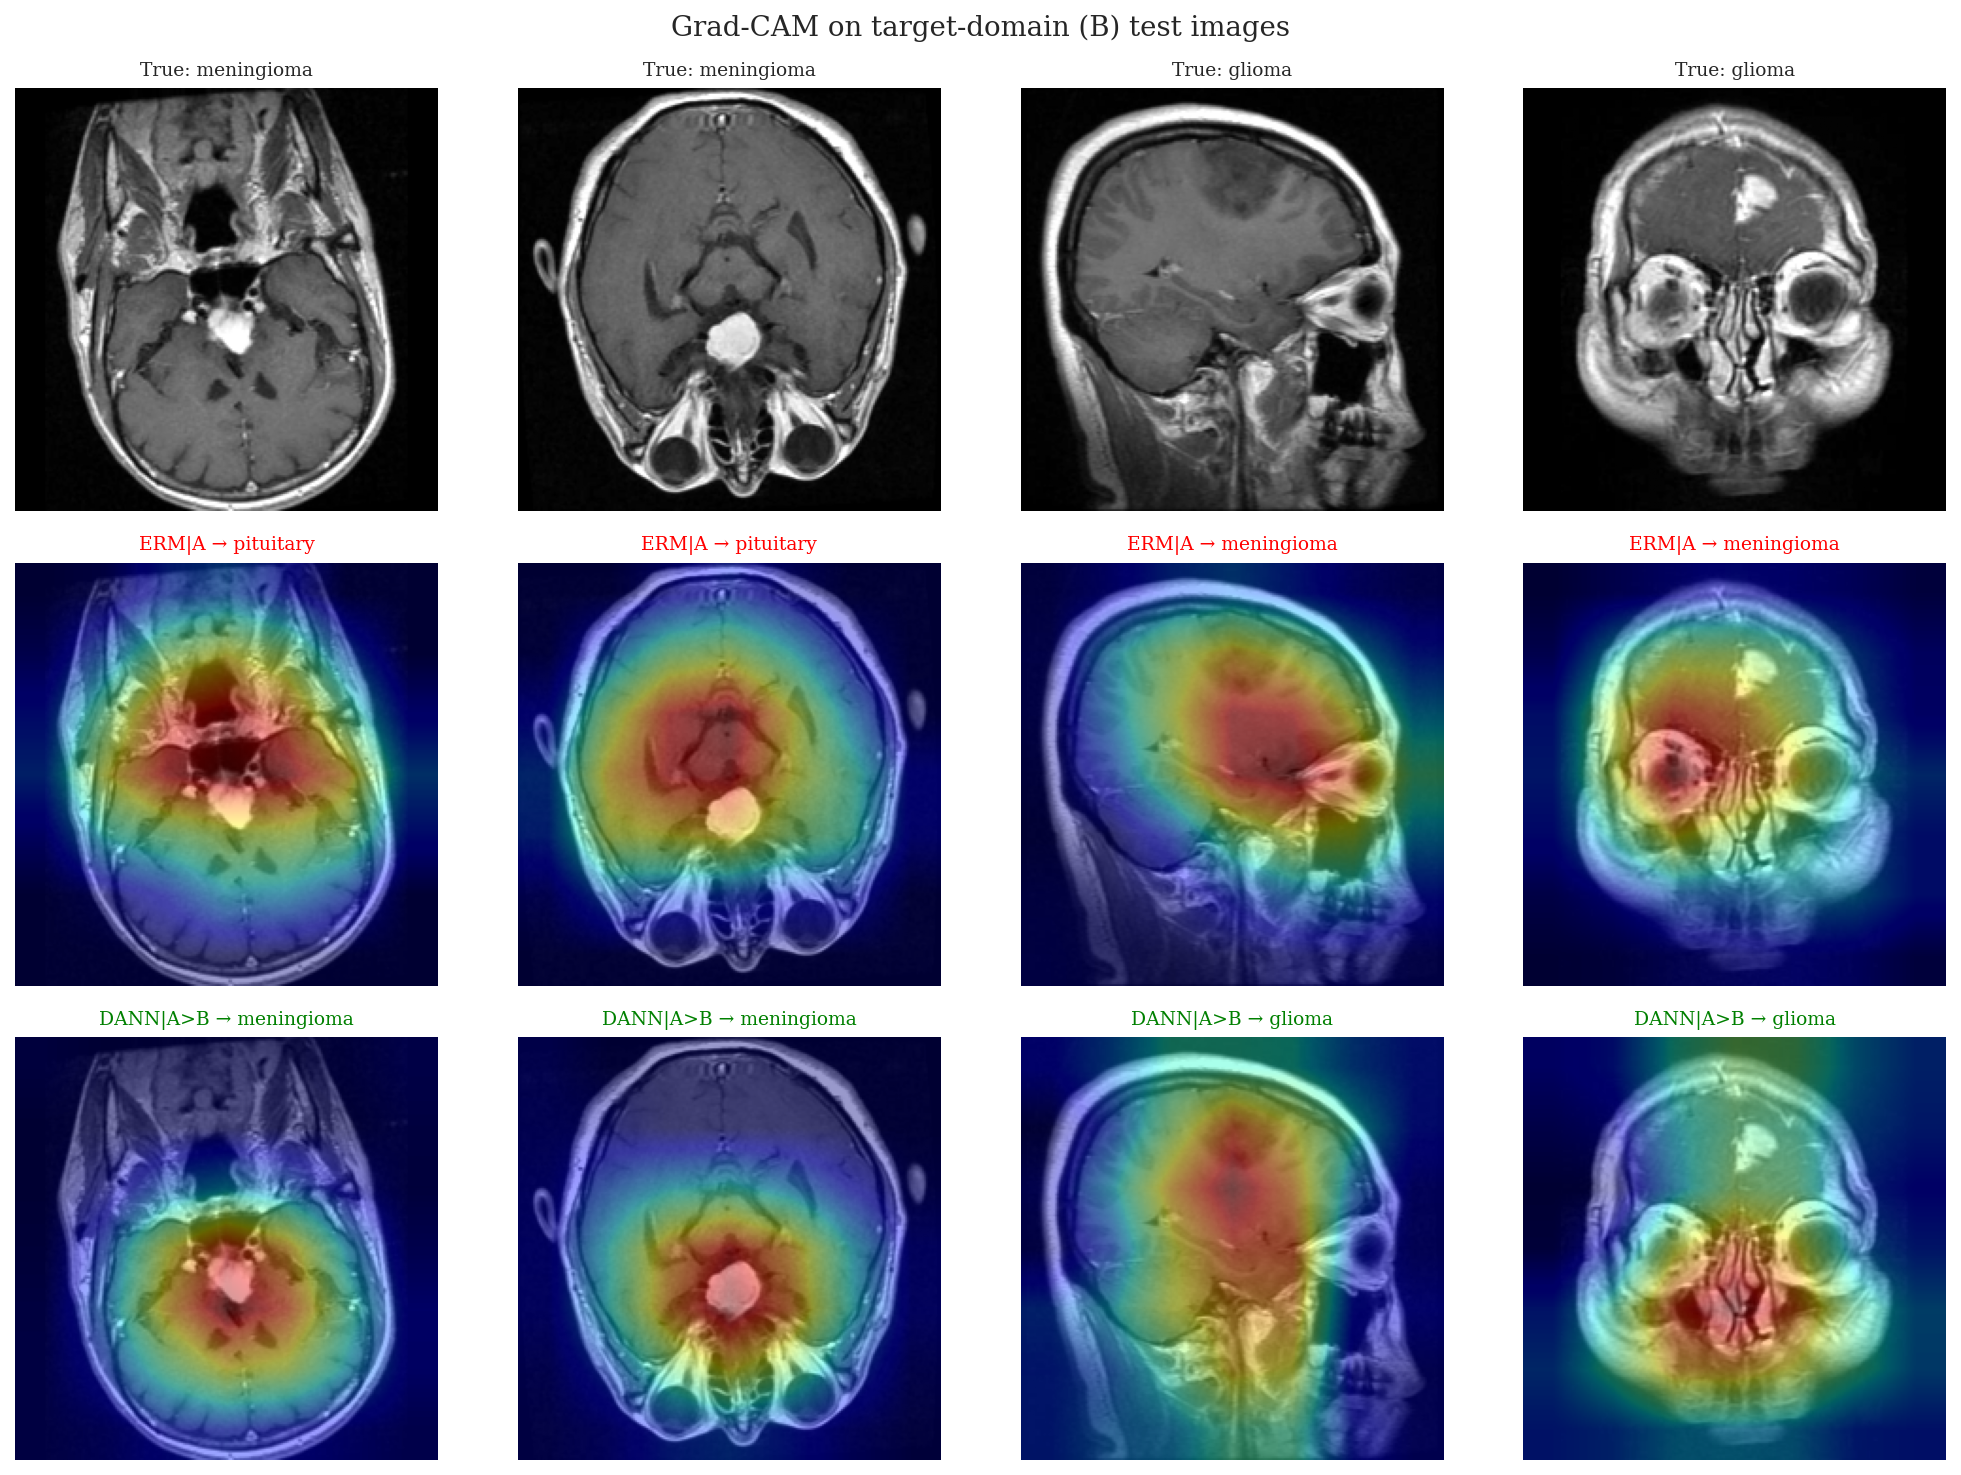

In [20]:
def gradcam(model, x, cls):
    acts, grads = {}, {}
    def fwd(m, i, o):
        acts["a"] = o; o.register_hook(lambda g: grads.__setitem__("g", g))
    h = model.bb.layer4[-1].register_forward_hook(fwd)
    model.eval(); model.zero_grad()
    with torch.enable_grad():
        x = x.clone().requires_grad_(True); lg, _, _ = model(x, 0.0); lg[0, cls].backward()
    h.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy()

s0_ = CFG.seeds[0]; yb = Y[EVAL["B_test"]]
p_erm  = RUNS[("ERM|A", s0_)]["logits"]["B_test"].argmax(1); p_dann = RUNS[("DANN-UDA|A>B", s0_)]["logits"]["B_test"].argmax(1)
fix = np.where((p_erm != yb) & (p_dann == yb))[0]; rng_g = np.random.RandomState(0)
pick = list(fix[:4]); rest = [i for i in rng_g.permutation(len(yb)) if i not in pick]; pick += rest[:max(0, 4 - len(pick))]
m_erm, m_dann = load_model("ERM|A"), load_model("DANN-UDA|A>B")
fig, axes = plt.subplots(3, len(pick), figsize=(3.4 * len(pick), 10))
for j, i in enumerate(pick):
    gi = EVAL["B_test"][i]; x = to_input(Xg[torch.tensor([gi], device=device)])
    axes[0, j].imshow(X[gi], cmap="gray"); axes[0, j].set_title(f"True: {CFG.class_names[yb[i]]}", fontsize=9)
    for r_, (mdl, pr, nm) in enumerate([(m_erm, p_erm, "ERM|A"), (m_dann, p_dann, "DANN|A>B")], start=1):
        cam = gradcam(mdl, x, int(pr[i])); axes[r_, j].imshow(X[gi], cmap="gray"); axes[r_, j].imshow(cam, cmap="jet", alpha=.4)
        axes[r_, j].set_title(f"{nm} → {CFG.class_names[pr[i]]}", fontsize=9, color="green" if pr[i] == yb[i] else "red")
    for a in axes[:, j]: a.axis("off")
plt.suptitle("Grad-CAM on target-domain (B) test images"
             + ("" if len(fix) else "  [no case where ERM fails and DANN succeeds — random samples shown]"))
savefig("fig9_gradcam.png")

## 14. Findings, generated from the statistics (not written by hand)
This cell turns the tables above into plain-language sentences and **will say "no reliable improvement" if that is what the data show**. Use these sentences — and only these — as the basis of your abstract.

In [21]:
lines = []
def g(q, ts): return comp_df[(comp_df.question == q) & (comp_df.test_set == ts)].iloc[0]

# 1. leakage
if "B_leaked" in EVAL:
    a = leak_df[(leak_df.model == "ERM|A") & (leak_df["eval"] == "B_test")].iloc[0]; b = leak_df[(leak_df.model == "ERM|A") & (leak_df["eval"] == "B_leaked")].iloc[0]
    infl = 100 * (b.acc - a.acc)
    lines.append(f"LEAKAGE: {len(B_dup)}/{len(B_all)} ({100*len(B_dup)/len(B_all):.1f}%) of Domain-B images are near-duplicates of Domain-A images (thumbnail correlation ≥ {CFG.dup_corr}). "
                 f"A source-only model trained on A scores {b.acc:.3f} on those twins vs {a.acc:.3f} on de-duplicated B — "
                 + (f"naive cross-dataset evaluation would overstate generalization by {infl:+.1f} accuracy points." if infl > 0 else
                    "no inflation observed on the twins (check the duplicate threshold and the label-agreement curve in Fig. 1)."))
# 2. shift
for eid, src, tgt, tag in [("ERM|A", "A_test", "B_test", "A→B"), ("ERM|B", "B_test", "A_test", "B→A")]:
    r_ = gap_df[gap_df.model == eid].iloc[0]
    lines.append(f"DOMAIN SHIFT {tag}: source-only accuracy is {r_.in_domain:.3f} in-domain vs {r_.cross_domain:.3f} on the unseen, de-duplicated domain "
                 + (f"(accuracy drops by {100*r_.gap:.1f} points under shift)." if r_.gap > 0.005 else
                    (f"(cross-domain accuracy is {100*abs(r_.gap):.1f} points HIGHER than in-domain — a leakage signature; re-check for residual overlap before trusting any cross-domain claim)." if r_.gap < -0.01 else
                     "(no measurable drop under shift).")))
# 3. DANN claims
for q, ts, tag in [("Does UDA beat source-only, A→B?", "B_test", "A→B"), ("Does UDA beat source-only, B→A?", "A_test", "B→A")]:
    r_ = g(q, ts); r2 = g(q.replace("source-only", "*strong-aug* source-only"), ts)
    lines.append(f"DANN (unsupervised DA) {tag}: vs. source-only {r_['diff']*100:+.2f} pts (95% CI {r_.ci_lo*100:+.2f} to {r_.ci_hi*100:+.2f}) → {r_.verdict}; "
                 f"vs. strong-augmentation baseline {r2['diff']*100:+.2f} pts (95% CI {r2.ci_lo*100:+.2f} to {r2.ci_hi*100:+.2f}) → {r2.verdict}.")
# 4. pooled control
for ts in ["A_test", "B_test"]:
    r_ = g(f"Adversary vs. no adversary when data are pooled ({ts[0]})", ts)
    lines.append(f"POOLED CONTROL ({ts}): adding the adversary to pooled labelled training changes accuracy by {r_['diff']*100:+.2f} pts (95% CI {r_.ci_lo*100:+.2f} to {r_.ci_hi*100:+.2f}) → {r_.verdict}.")
# 5. invariance
if "ERM|A" in probe and "DANN-UDA|A>B" in probe:
    lines.append(f"INVARIANCE (A→B): domain-probe accuracy {probe['ERM|A'].mean():.3f} (source-only) → {probe['DANN-UDA|A>B'].mean():.3f} (DANN); chance = 0.5.")
lines.append(f"PROTOCOL: {len(CFG.seeds)} seed(s), grouped splits, model selection on source validation only, hyper-parameters fixed a priori; test images: A={len(A_te)}, B={len(B_te)}.")

print("\n\n".join("• " + l for l in lines))

summary = dict(config={k: v for k, v in vars(CFG).items() if not k.startswith("_")}, findings=lines,
               main=main_df.to_dict("records"), paired_tests=comp_df.to_dict("records"), domain_gap=gap_df.to_dict("records"),
               domain_probe=probe_df.to_dict("records"), uncertainty=unc_df.to_dict("records"),
               duplicate_sensitivity=sens.to_dict("records"))
json.dump(summary, open(os.path.join(CFG.out_dir, "results_summary.json"), "w"), indent=2, default=str)
print("\nSaved: results_summary.json, table1–7 (.csv) and figures in", FIG_DIR); print(sorted(os.listdir(FIG_DIR)))

• LEAKAGE: 2866/7200 (39.8%) of Domain-B images are near-duplicates of Domain-A images (thumbnail correlation ≥ 0.9). A source-only model trained on A scores 0.995 on those twins vs 0.975 on de-duplicated B — naive cross-dataset evaluation would overstate generalization by +2.0 accuracy points.

• DOMAIN SHIFT A→B: source-only accuracy is 0.932 in-domain vs 0.975 on the unseen, de-duplicated domain (cross-domain accuracy is 4.3 points HIGHER than in-domain — a leakage signature; re-check for residual overlap before trusting any cross-domain claim).

• DOMAIN SHIFT B→A: source-only accuracy is 0.984 in-domain vs 0.894 on the unseen, de-duplicated domain (accuracy drops by 8.9 points under shift).

• DANN (unsupervised DA) A→B: vs. source-only -2.32 pts (95% CI -3.21 to -1.47) → hurts; vs. strong-augmentation baseline +1.16 pts (95% CI -0.13 to +2.45) → no reliable difference.

• DANN (unsupervised DA) B→A: vs. source-only -3.33 pts (95% CI -5.38 to -1.21) → hurts; vs. strong-augmentatio

## 15. How to turn this into an honest abstract (≤ 500 words, no figures)

**If DANN improves target accuracy with a CI that excludes 0 *and* also beats the strong-augmentation baseline:** state the effect with its CI, name the number of seeds, and say the target labels were never used. Mention the Pooled control (whether the adversary helps beyond pooling).

**If it does not (the most likely outcome on datasets this saturated):** that is still a publishable, useful result. Frame the contribution as:
1. *a leakage audit* — the percentage of an "independent" public benchmark that is near-duplicate of another, and how much it inflates cross-dataset accuracy (§4, §10c);
2. *a rigorous negative/neutral result* — domain-adversarial training gives no reliable gain over strong augmentation on de-duplicated data (§10b), with quantified domain invariance (§11);
3. *a reusable protocol* — duplicate-aware, grouped, multi-seed evaluation.

**Do not** report in-domain accuracy as evidence of generalization, and do not tune `lambda_max`, epochs or the duplicate threshold after looking at test results.

## Limitations (say these in the abstract/poster)
* **No patient IDs.** Grouping by near-duplicate clusters removes copies and many adjacent slices but cannot guarantee patient-level separation; in-domain numbers may still be optimistic. The cross-domain numbers are much less affected because A and B\_clean are disjoint by construction.
* **Correlation-based duplicate detection is a heuristic.** Copies that were flipped, rotated or heavily re-cropped can evade it (residual overlap would make cross-domain results *optimistic*), while a threshold that is too low removes genuinely different look-alike slices; the sensitivity curve (Fig. 1) shows how the removed fraction depends on the threshold.
* **B is itself a composite** (figshare + Br35H + a Sartaj subset), so "domain B" is a mixture of sources, not a single scanner. Source-level metadata is not available.
* **Two datasets, one architecture, 2D slices, 4 classes.** Results should not be read as clinical validity.
* Bootstrap CIs capture test-set sampling noise; the across-seed sd captures training noise; neither captures variation across different train/test partitions.

In [22]:
"""
Methodology workflow figure for the current notebook.
Counts are inserted dynamically from the indexed datasets so no stale sample
counts are hard-coded into the figure.
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

nA = int((meta.domain == 0).sum())
nB = int((meta.domain == 1).sum())
nBclean = int(meta[(meta.domain == 1) & meta.keep].shape[0])

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

def box(x, y, w, h, title, body):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=1",
                                fc="#edf1f7", ec="#333", lw=1))
    ax.text(x+w/2, y+h*0.68, title, ha="center", va="center", fontsize=9, weight="bold")
    ax.text(x+w/2, y+h*0.32, body, ha="center", va="center", fontsize=8)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle="-|>",mutation_scale=12,lw=1,color="#333"))

box(3, 78, 27, 14, "Domain A", f"{nA:,} indexed images")
box(70, 78, 27, 14, "Domain B", f"{nB:,} indexed images")
box(31, 57, 38, 14, "Duplicate audit", f"Pearson r threshold = {CFG.dup_corr:.2f}\nB clean = {nBclean:,}")
arrow(16,78,42,71); arrow(83,78,58,71)
box(26, 35, 48, 14, "Grouped partitions", "Near-duplicate clusters kept within splits\ntrain / validation / test")
arrow(50,57,50,49)
box(2, 9, 29, 15, "Model arms", "ERM · strong augmentation\nDANN-UDA · pooled controls")
box(36, 9, 29, 15, "Evaluation", "A-test and B-clean-test\npaired bootstrap CIs")
box(70, 9, 28, 15, "Diagnostics", "Domain probe · MC-dropout\nGrad-CAM · t-SNE")
arrow(40,35,16,24); arrow(50,35,50,24); arrow(60,35,84,24)
fig.savefig(os.path.join(FIG_DIR, "fig_workflow.png"), dpi=300, bbox_inches="tight")
plt.show()
print("Saved workflow figure:", os.path.join(FIG_DIR, "fig_workflow.png"))


Saved workflow figure: /kaggle/working/outputs/figures/fig_workflow.png
